In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.compose import ColumnTransformer

from xgboost import XGBRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.ensemble import AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor

from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score,mean_absolute_error

!pip install optuna
import optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 265.9/265.9 kB 12.1 MB/s eta 0:00:00


In [ ]:
import datetime as dt

In [ ]:
data=pd.read_csv('Solar Power Plant Data.csv')
data

,Date-Hour(NMT),WindSpeed,Sunshine,AirPressure,Radiation,AirTemperature,RelativeAirHumidity,SystemProduction
0,01.01.2017-00:00,0.6,0,1003.8,-7.4,0.1,97,0.0
1,01.01.2017-01:00,1.7,0,1003.5,-7.4,-0.2,98,0.0
2,01.01.2017-02:00,0.6,0,1003.4,-6.7,-1.2,99,0.0
3,01.01.2017-03:00,2.4,0,1003.3,-7.2,-1.3,99,0.0
4,01.01.2017-04:00,4.0,0,1003.1,-6.3,3.6,67,0.0
...,...,...,...,...,...,...,...,...
8755,31.12.2017-19:00,4.1,0,988.2,-4.8,-0.7,94,0.0
8756,31.12.2017-20:00,2.1,0,987.3,-5.0,-0.3,95,0.0
8757,31.12.2017-21:00,1.8,0,986.7,-5.3,0.2,93,0.0
8758,31.12.2017-22:00,2.2,0,986.0,-5.4,0.3,92,0.0


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Date-Hour(NMT)       8760 non-null   object 
 1   WindSpeed            8760 non-null   float64
 2   Sunshine             8760 non-null   int64  
 3   AirPressure          8760 non-null   float64
 4   Radiation            8760 non-null   float64
 5   AirTemperature       8760 non-null   float64
 6   RelativeAirHumidity  8760 non-null   int64  
 7   SystemProduction     8760 non-null   float64
dtypes: float64(5), int64(2), object(1)
memory usage: 547.6+ KB


In [ ]:
data.columns

Index(['Date-Hour(NMT)', 'WindSpeed', 'Sunshine', 'AirPressure', 'Radiation',
       'AirTemperature', 'RelativeAirHumidity', 'SystemProduction'],
      dtype='object')

In [ ]:
data['Date-Hour(NMT)']=pd.to_datetime(data['Date-Hour(NMT)'], format="%d.%m.%Y-%H:%M")

In [ ]:
data['Date-Hour(NMT)'].dtype

dtype('<M8[ns]')

In [ ]:
data.duplicated().sum()

np.int64(0)

In [ ]:
(data.isnull().sum()/len(data))*100

,0
Date-Hour(NMT),0.0
WindSpeed,0.0
Sunshine,0.0
AirPressure,0.0
Radiation,0.0
AirTemperature,0.0
RelativeAirHumidity,0.0
SystemProduction,0.0


In [ ]:
data.describe()

,Date-Hour(NMT),WindSpeed,Sunshine,AirPressure,Radiation,AirTemperature,RelativeAirHumidity,SystemProduction
count,8760,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000
mean,2017-07-02 11:30:00,2.639823,11.180479,1010.361781,97.538493,6.978893,76.719406,684.746071
min,2017-01-01 00:00:00,0.000000,0.000000,965.900000,-9.300000,-12.400000,13.000000,0.000000
25%,2017-04-02 05:45:00,1.400000,0.000000,1002.800000,-6.200000,0.500000,64.000000,0.000000
50%,2017-07-02 11:30:00,2.300000,0.000000,1011.000000,-1.400000,6.400000,82.000000,0.000000
75%,2017-10-01 17:15:00,3.600000,7.000000,1018.200000,115.600000,13.400000,93.000000,464.249950
max,2017-12-31 23:00:00,10.900000,60.000000,1047.300000,899.700000,27.100000,100.000000,7701.000000
std,NaN,1.628754,21.171295,12.793971,182.336029,7.604266,19.278996,1487.454665


In [ ]:
corr=data.corr(numeric_only=True)
corr

,WindSpeed,Sunshine,AirPressure,Radiation,AirTemperature,RelativeAirHumidity,SystemProduction
WindSpeed,1.000000,0.123627,-0.028988,0.191142,0.191490,-0.340053,0.195650
Sunshine,0.123627,1.000000,0.064096,0.776288,0.376184,-0.613761,0.564228
AirPressure,-0.028988,0.064096,1.000000,0.054565,-0.028731,-0.111853,-0.004487
Radiation,0.191142,0.776288,0.054565,1.000000,0.535159,-0.627944,0.785717
AirTemperature,0.191490,0.376184,-0.028731,0.535159,1.000000,-0.389777,0.480407
RelativeAirHumidity,-0.340053,-0.613761,-0.111853,-0.627944,-0.389777,1.000000,-0.545252
SystemProduction,0.195650,0.564228,-0.004487,0.785717,0.480407,-0.545252,1.000000


In [ ]:
data['Hour']=data['Date-Hour(NMT)'].dt.hour

In [ ]:
data['Month']=data['Date-Hour(NMT)'].dt.month

In [ ]:
data['Year']=data['Date-Hour(NMT)'].dt.year

In [ ]:
data['Day']=data['Date-Hour(NMT)'].dt.day

In [ ]:
data['Week']=data['Date-Hour(NMT)'].dt.isocalendar().week

In [ ]:
def day_or_not(hour):
    if hour<6 or hour>19:
      return 'night'
    else:
      return 'day'

In [ ]:
data['Day/Night']=data['Hour'].apply(day_or_not)

In [ ]:
data

,Date-Hour(NMT),WindSpeed,Sunshine,AirPressure,Radiation,AirTemperature,RelativeAirHumidity,SystemProduction,Hour,Month,Year,Day,Week,Day/Night
0,2017-01-01 00:00:00,0.6,0,1003.8,-7.4,0.1,97,0.0,0,1,2017,1,52,night
1,2017-01-01 01:00:00,1.7,0,1003.5,-7.4,-0.2,98,0.0,1,1,2017,1,52,night
2,2017-01-01 02:00:00,0.6,0,1003.4,-6.7,-1.2,99,0.0,2,1,2017,1,52,night
3,2017-01-01 03:00:00,2.4,0,1003.3,-7.2,-1.3,99,0.0,3,1,2017,1,52,night
4,2017-01-01 04:00:00,4.0,0,1003.1,-6.3,3.6,67,0.0,4,1,2017,1,52,night
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,2017-12-31 19:00:00,4.1,0,988.2,-4.8,-0.7,94,0.0,19,12,2017,31,52,day
8756,2017-12-31 20:00:00,2.1,0,987.3,-5.0,-0.3,95,0.0,20,12,2017,31,52,night
8757,2017-12-31 21:00:00,1.8,0,986.7,-5.3,0.2,93,0.0,21,12,2017,31,52,night
8758,2017-12-31 22:00:00,2.2,0,986.0,-5.4,0.3,92,0.0,22,12,2017,31,52,night


In [ ]:
data['Radiation_Norm']=data['Radiation']/data['Radiation'].max()

In [ ]:
data['Radiation_Cum']=data.groupby('Day')['Radiation'].cumsum()

In [ ]:
data

,Date-Hour(NMT),WindSpeed,Sunshine,AirPressure,Radiation,AirTemperature,RelativeAirHumidity,SystemProduction,Hour,Month,Year,Day,Week,Day/Night,Radiation_Norm,Radiation_Cum
0,2017-01-01 00:00:00,0.6,0,1003.8,-7.4,0.1,97,0.0,0,1,2017,1,52,night,-0.008225,-7.4
1,2017-01-01 01:00:00,1.7,0,1003.5,-7.4,-0.2,98,0.0,1,1,2017,1,52,night,-0.008225,-14.8
2,2017-01-01 02:00:00,0.6,0,1003.4,-6.7,-1.2,99,0.0,2,1,2017,1,52,night,-0.007447,-21.5
3,2017-01-01 03:00:00,2.4,0,1003.3,-7.2,-1.3,99,0.0,3,1,2017,1,52,night,-0.008003,-28.7
4,2017-01-01 04:00:00,4.0,0,1003.1,-6.3,3.6,67,0.0,4,1,2017,1,52,night,-0.007002,-35.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,2017-12-31 19:00:00,4.1,0,988.2,-4.8,-0.7,94,0.0,19,12,2017,31,52,day,-0.005335,12358.4
8756,2017-12-31 20:00:00,2.1,0,987.3,-5.0,-0.3,95,0.0,20,12,2017,31,52,night,-0.005557,12353.4
8757,2017-12-31 21:00:00,1.8,0,986.7,-5.3,0.2,93,0.0,21,12,2017,31,52,night,-0.005891,12348.1
8758,2017-12-31 22:00:00,2.2,0,986.0,-5.4,0.3,92,0.0,22,12,2017,31,52,night,-0.006002,12342.7


In [ ]:
data.drop(columns=['Date-Hour(NMT)'],inplace=True)

In [ ]:
data

,WindSpeed,Sunshine,AirPressure,Radiation,AirTemperature,RelativeAirHumidity,SystemProduction,Hour,Month,Year,Day,Week,Day/Night,Radiation_Norm,Radiation_Cum
0,0.6,0,1003.8,-7.4,0.1,97,0.0,0,1,2017,1,52,night,-0.008225,-7.4
1,1.7,0,1003.5,-7.4,-0.2,98,0.0,1,1,2017,1,52,night,-0.008225,-14.8
2,0.6,0,1003.4,-6.7,-1.2,99,0.0,2,1,2017,1,52,night,-0.007447,-21.5
3,2.4,0,1003.3,-7.2,-1.3,99,0.0,3,1,2017,1,52,night,-0.008003,-28.7
4,4.0,0,1003.1,-6.3,3.6,67,0.0,4,1,2017,1,52,night,-0.007002,-35.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,4.1,0,988.2,-4.8,-0.7,94,0.0,19,12,2017,31,52,day,-0.005335,12358.4
8756,2.1,0,987.3,-5.0,-0.3,95,0.0,20,12,2017,31,52,night,-0.005557,12353.4
8757,1.8,0,986.7,-5.3,0.2,93,0.0,21,12,2017,31,52,night,-0.005891,12348.1
8758,2.2,0,986.0,-5.4,0.3,92,0.0,22,12,2017,31,52,night,-0.006002,12342.7


In [ ]:
corr=data.corr(numeric_only=True)
corr

,WindSpeed,Sunshine,AirPressure,Radiation,AirTemperature,RelativeAirHumidity,SystemProduction,Hour,Month,Year,Day,Week,Radiation_Norm,Radiation_Cum
WindSpeed,1.000000,0.123627,-0.028988,0.191142,0.191490,-0.340053,0.195650,8.359692e-02,2.408371e-02,NaN,3.479126e-02,2.455780e-02,0.191142,0.043809
Sunshine,0.123627,1.000000,0.064096,0.776288,0.376184,-0.613761,0.564228,1.080170e-01,-4.103611e-02,NaN,-2.361474e-03,-4.268093e-02,0.776288,-0.002924
AirPressure,-0.028988,0.064096,1.000000,0.054565,-0.028731,-0.111853,-0.004487,-1.296946e-02,-2.668546e-01,NaN,-6.851861e-03,-2.678285e-01,0.054565,-0.185008
Radiation,0.191142,0.776288,0.054565,1.000000,0.535159,-0.627944,0.785717,1.041667e-01,-6.266375e-02,NaN,1.721214e-02,-6.727965e-02,1.000000,-0.014819
AirTemperature,0.191490,0.376184,-0.028731,0.535159,1.000000,-0.389777,0.480407,1.201327e-01,1.628389e-01,NaN,4.833528e-02,1.555922e-01,0.535159,0.263300
RelativeAirHumidity,-0.340053,-0.613761,-0.111853,-0.627944,-0.389777,1.000000,-0.545252,-1.715701e-01,9.293024e-02,NaN,-3.015758e-02,8.774162e-02,-0.627944,0.042536
SystemProduction,0.195650,0.564228,-0.004487,0.785717,0.480407,-0.545252,1.000000,1.606716e-01,-3.499034e-02,NaN,2.960773e-02,-3.788817e-02,0.785717,0.031878
Hour,0.083597,0.108017,-0.012969,0.104167,0.120133,-0.171570,0.160672,1.000000e+00,2.564176e-15,NaN,1.702457e-16,2.554908e-15,0.104167,0.084115
Month,0.024084,-0.041036,-0.266855,-0.062664,0.162839,0.092930,-0.034990,2.564176e-15,1.000000e+00,NaN,1.189318e-02,9.814410e-01,-0.062664,0.919770
Year,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


<Axes: >

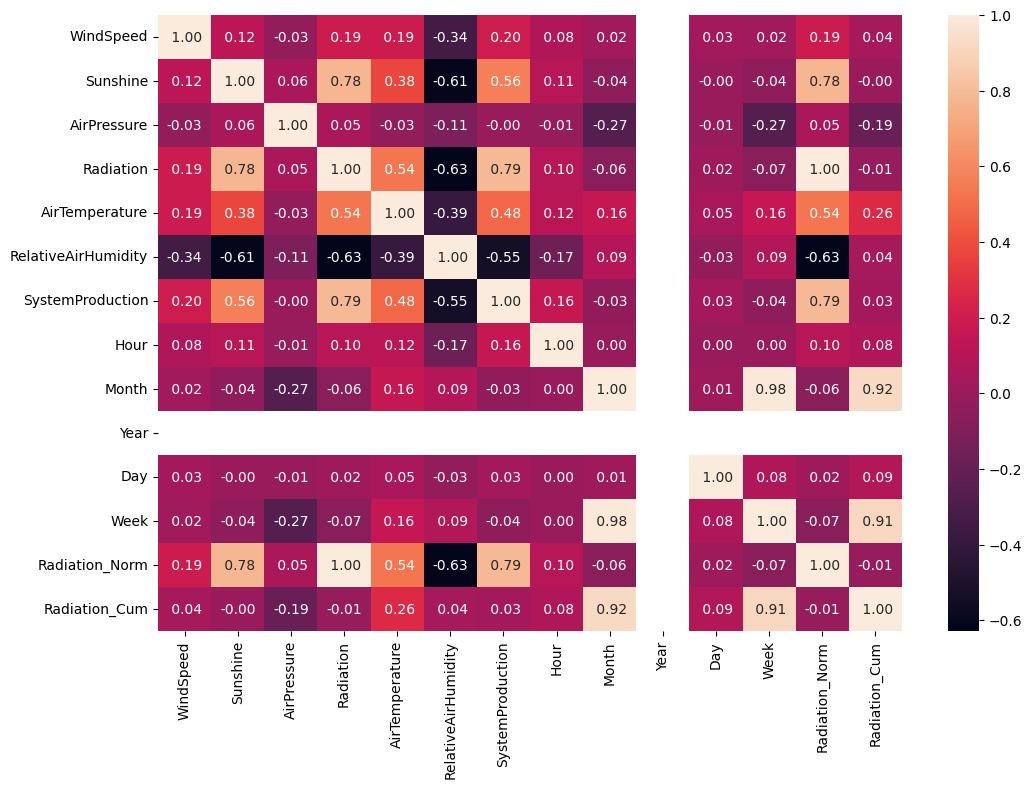

In [ ]:
plt.figure(figsize=(12,8))
sns.heatmap(corr,annot=True,fmt=' .2f')

In [ ]:
num=data.drop(columns=['Day/Night'])
num

,WindSpeed,Sunshine,AirPressure,Radiation,AirTemperature,RelativeAirHumidity,SystemProduction,Hour,Month,Year,Day,Week,Radiation_Norm,Radiation_Cum
0,0.6,0,1003.8,-7.4,0.1,97,0.0,0,1,2017,1,52,-0.008225,-7.4
1,1.7,0,1003.5,-7.4,-0.2,98,0.0,1,1,2017,1,52,-0.008225,-14.8
2,0.6,0,1003.4,-6.7,-1.2,99,0.0,2,1,2017,1,52,-0.007447,-21.5
3,2.4,0,1003.3,-7.2,-1.3,99,0.0,3,1,2017,1,52,-0.008003,-28.7
4,4.0,0,1003.1,-6.3,3.6,67,0.0,4,1,2017,1,52,-0.007002,-35.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,4.1,0,988.2,-4.8,-0.7,94,0.0,19,12,2017,31,52,-0.005335,12358.4
8756,2.1,0,987.3,-5.0,-0.3,95,0.0,20,12,2017,31,52,-0.005557,12353.4
8757,1.8,0,986.7,-5.3,0.2,93,0.0,21,12,2017,31,52,-0.005891,12348.1
8758,2.2,0,986.0,-5.4,0.3,92,0.0,22,12,2017,31,52,-0.006002,12342.7


/tmp/ipykernel_680/3091331060.py:6: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(data[col])


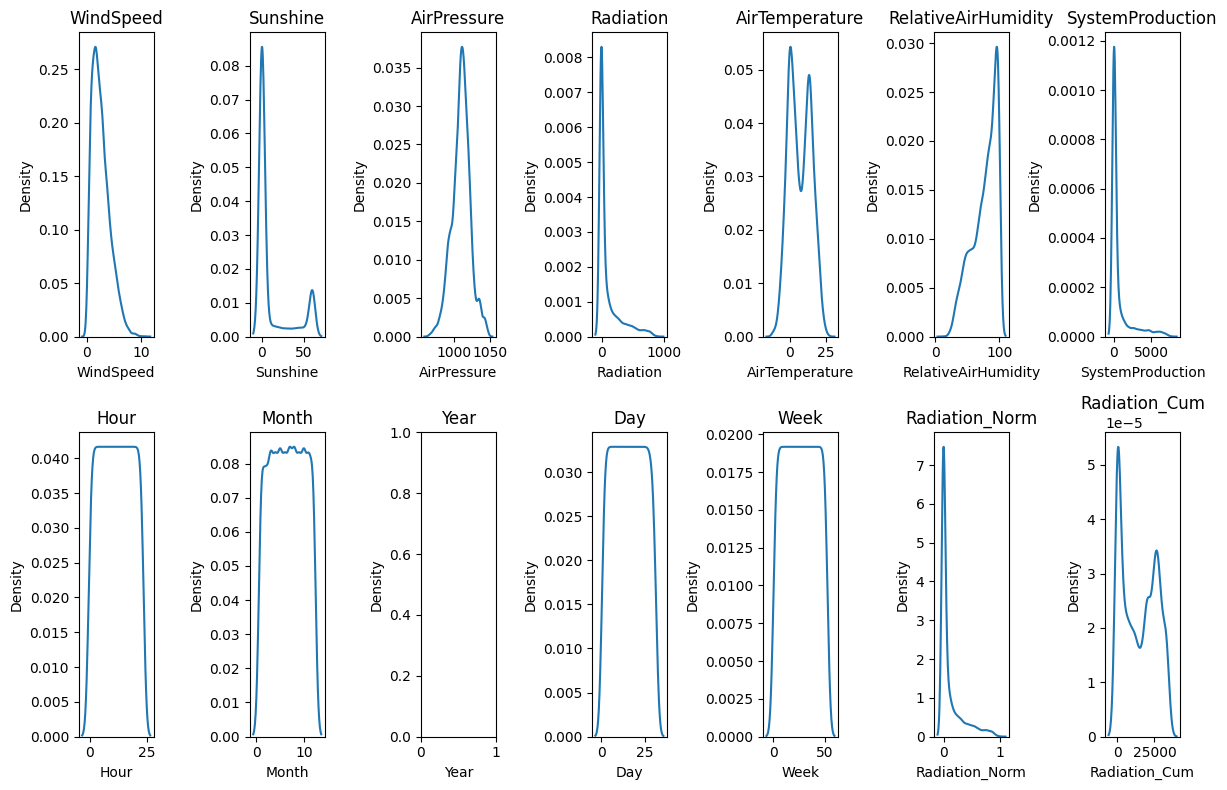

In [ ]:
plt.figure(figsize=(12,8))

for index,col in enumerate(num):

  plt.subplot(2,7,index+1)
  sns.kdeplot(data[col])
  plt.title(col)
  plt.tight_layout()
plt.show()

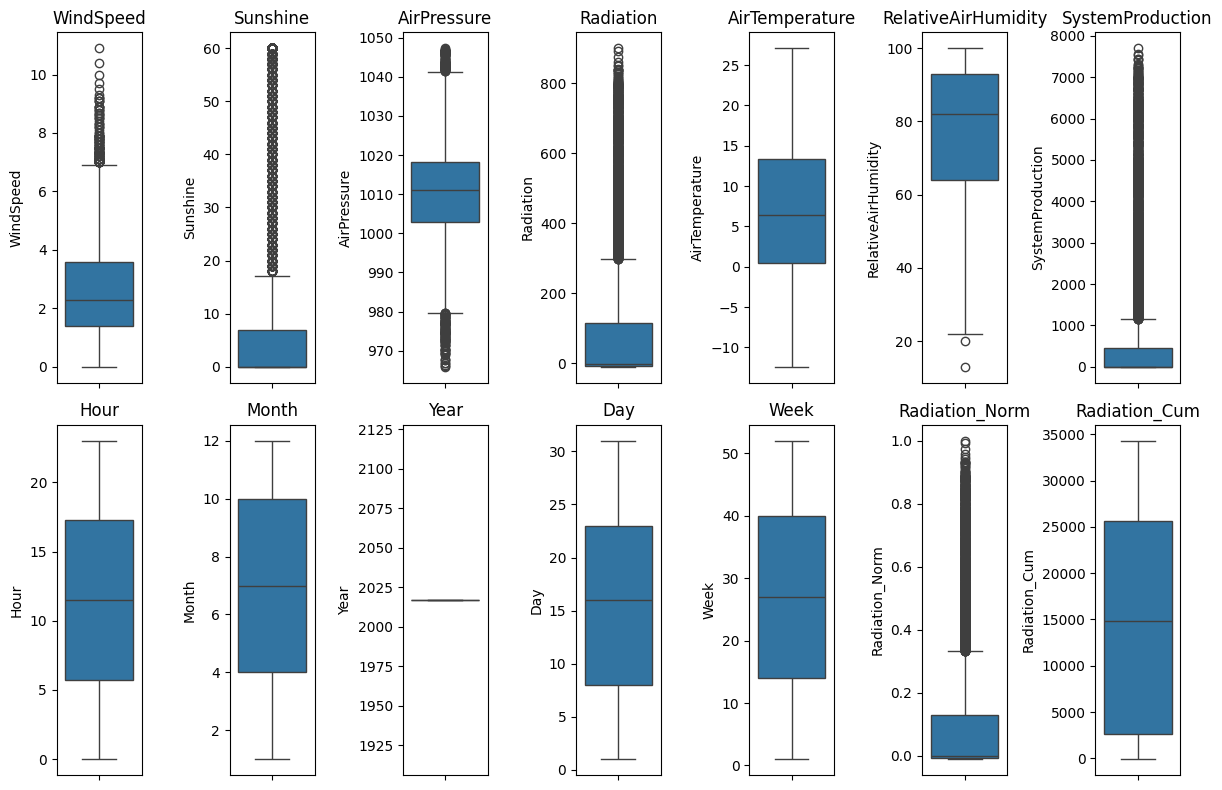

In [ ]:
plt.figure(figsize=(12,8))

for index,col in enumerate(num):

  plt.subplot(2,7,index+1)
  sns.boxplot(data[col])
  plt.title(col)
  plt.tight_layout()
plt.show()

<Axes: xlabel='count', ylabel='Day/Night'>

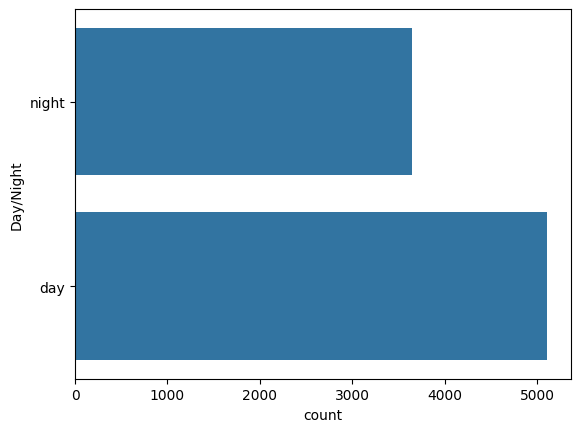

In [ ]:
sns.countplot(data['Day/Night'])

<Axes: xlabel='Month', ylabel='SystemProduction'>

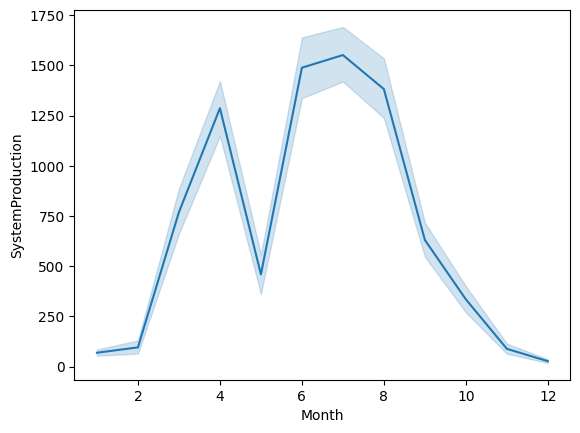

In [ ]:
sns.lineplot(x=data['Month'],y=data['SystemProduction'])

<Axes: xlabel='Hour', ylabel='SystemProduction'>

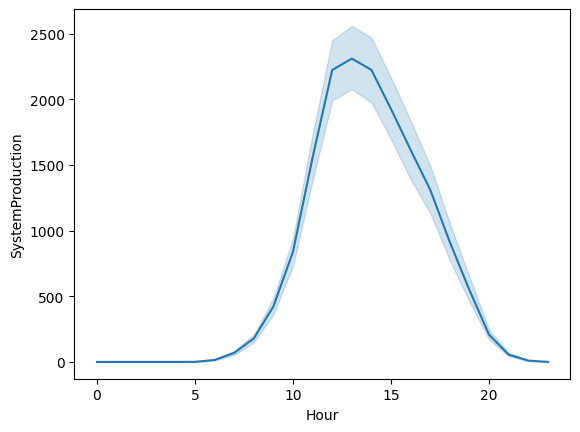

In [ ]:
sns.lineplot(x=data['Hour'],y=data['SystemProduction'])

<Axes: xlabel='Week', ylabel='SystemProduction'>

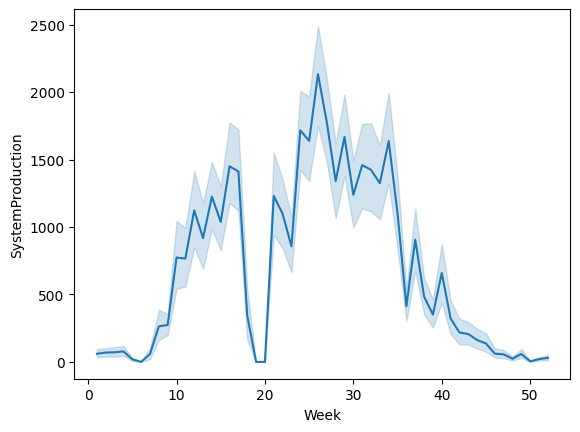

In [ ]:
sns.lineplot(x=data['Week'],y=data['SystemProduction'])

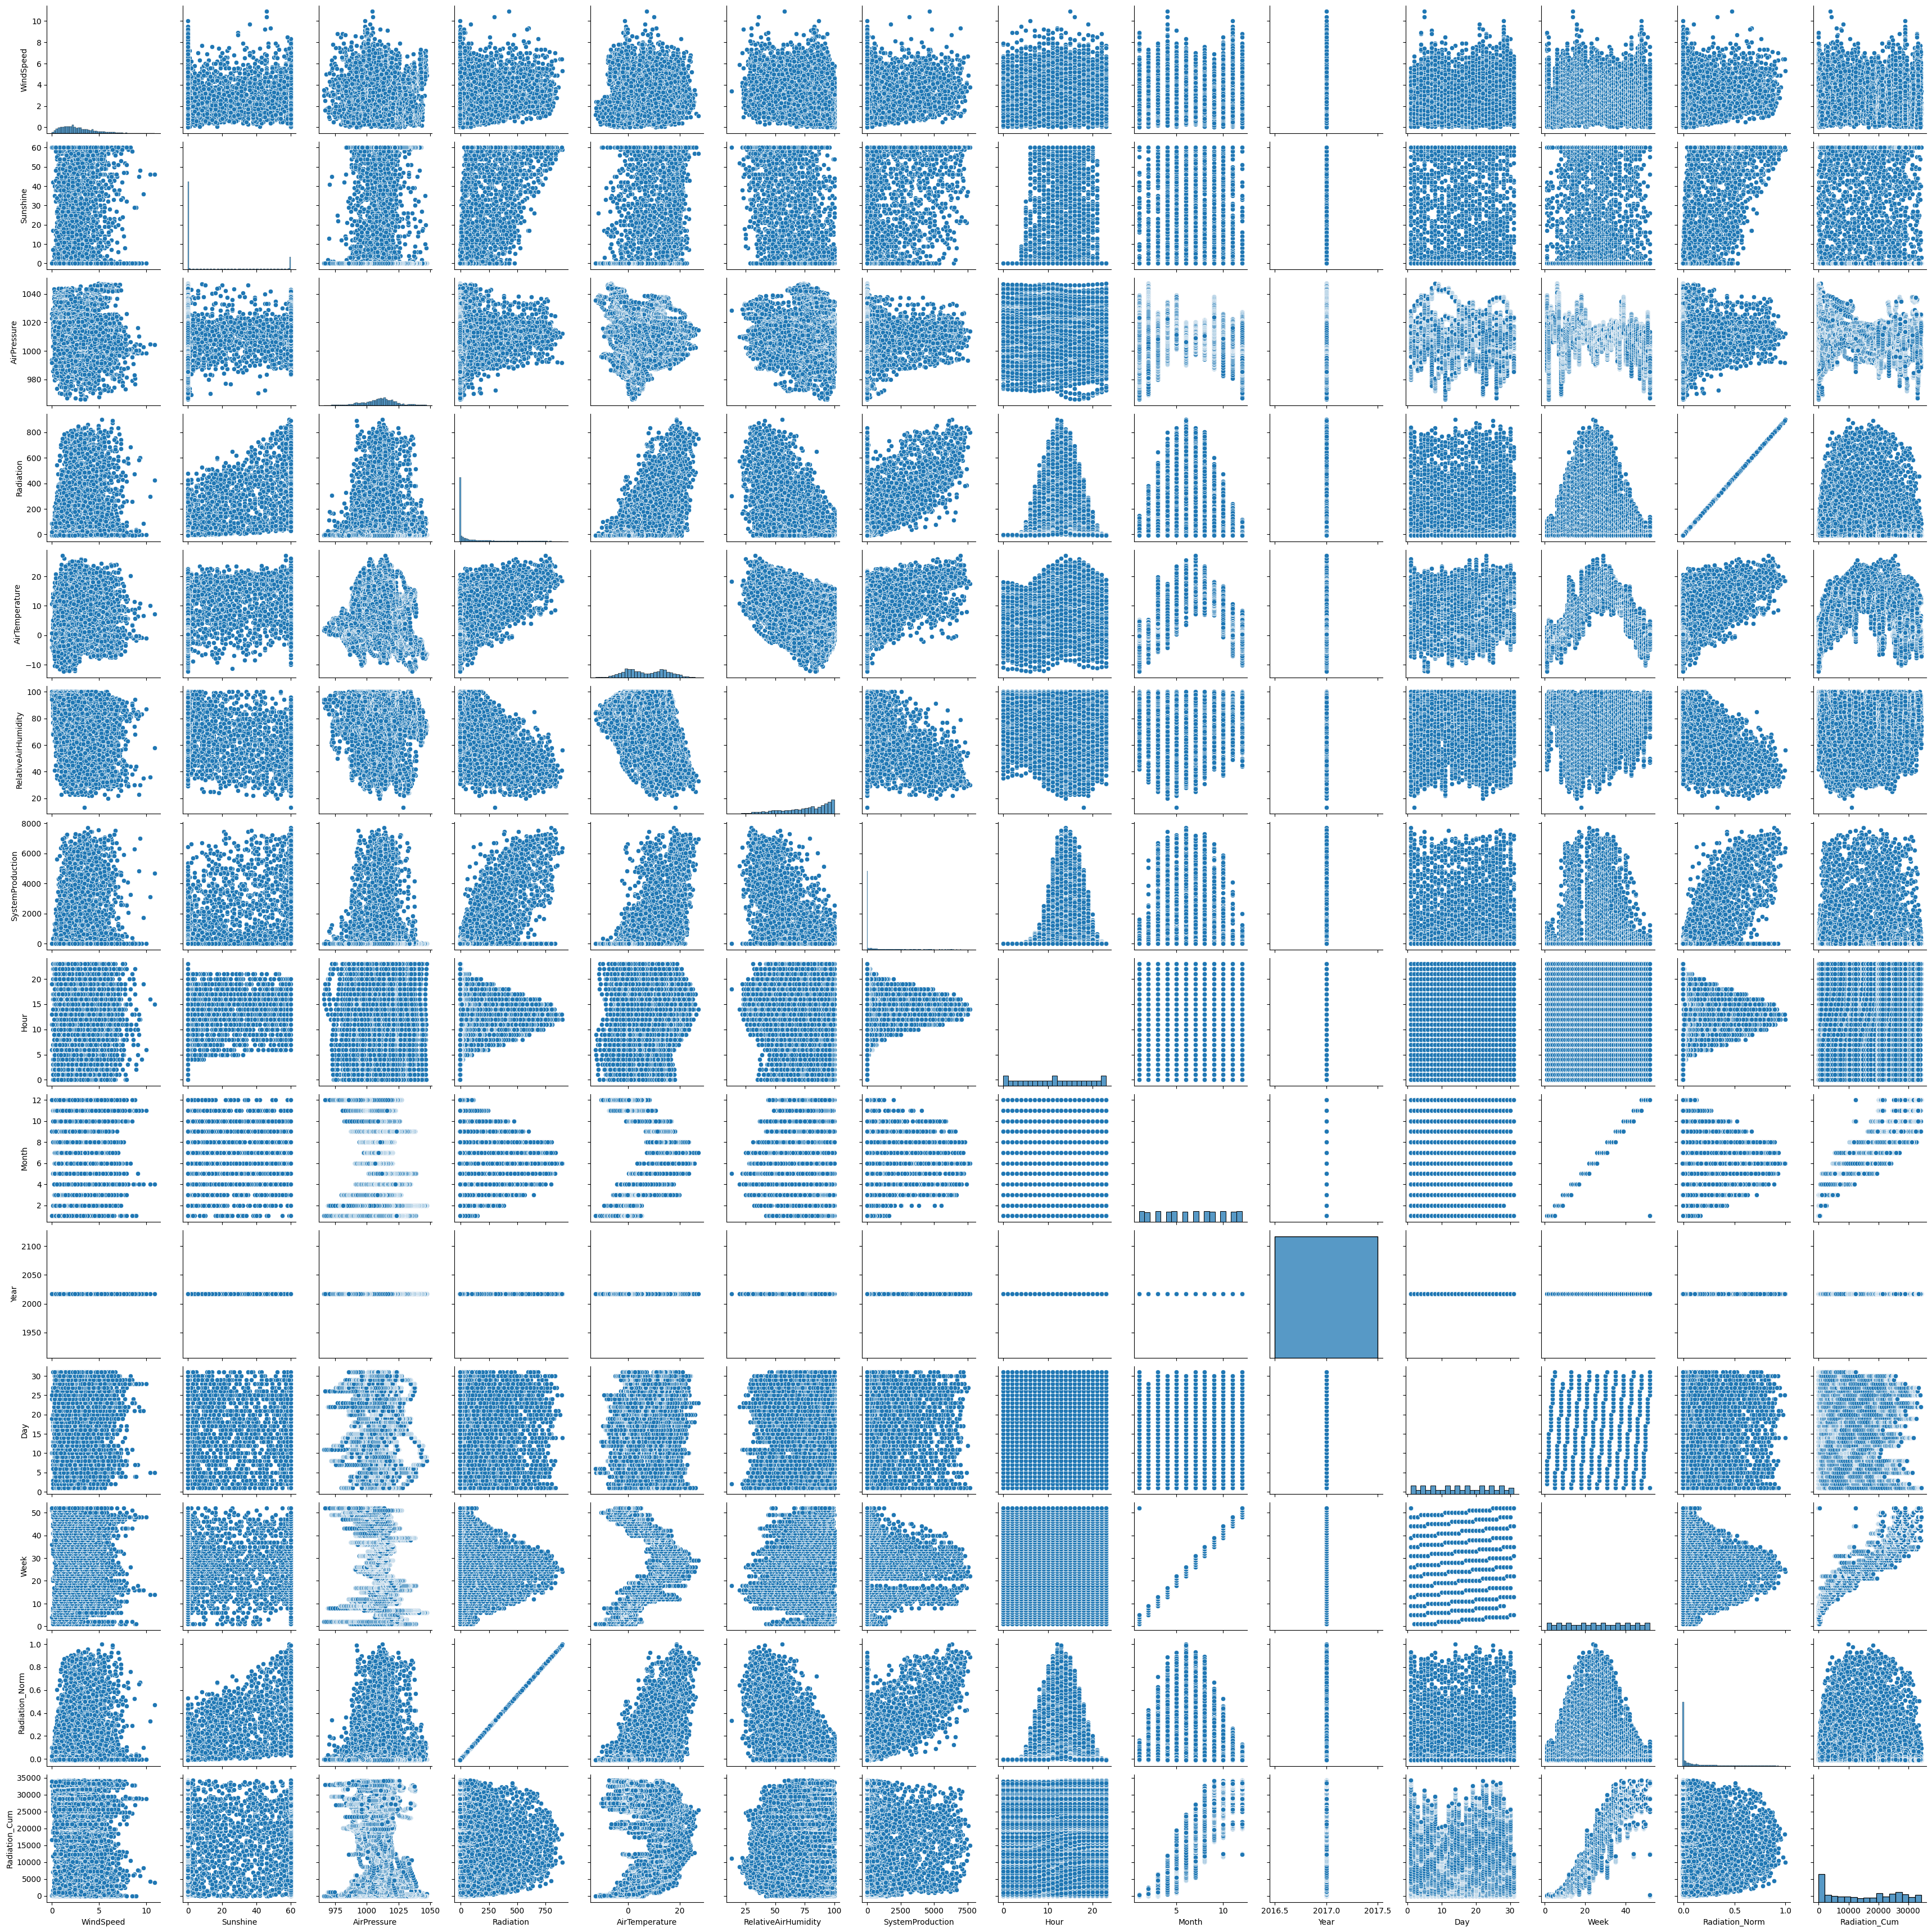

In [ ]:
sns.pairplot(num)

In [ ]:
x=data.drop(columns=['SystemProduction'])
x

,WindSpeed,Sunshine,AirPressure,Radiation,AirTemperature,RelativeAirHumidity,Hour,Month,Year,Day,Week,Day/Night,Radiation_Norm,Radiation_Cum
0,0.6,0,1003.8,-7.4,0.1,97,0,1,2017,1,52,night,-0.008225,-7.4
1,1.7,0,1003.5,-7.4,-0.2,98,1,1,2017,1,52,night,-0.008225,-14.8
2,0.6,0,1003.4,-6.7,-1.2,99,2,1,2017,1,52,night,-0.007447,-21.5
3,2.4,0,1003.3,-7.2,-1.3,99,3,1,2017,1,52,night,-0.008003,-28.7
4,4.0,0,1003.1,-6.3,3.6,67,4,1,2017,1,52,night,-0.007002,-35.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,4.1,0,988.2,-4.8,-0.7,94,19,12,2017,31,52,day,-0.005335,12358.4
8756,2.1,0,987.3,-5.0,-0.3,95,20,12,2017,31,52,night,-0.005557,12353.4
8757,1.8,0,986.7,-5.3,0.2,93,21,12,2017,31,52,night,-0.005891,12348.1
8758,2.2,0,986.0,-5.4,0.3,92,22,12,2017,31,52,night,-0.006002,12342.7


In [ ]:
y=data['SystemProduction']
y

,SystemProduction
0,0.0
1,0.0
2,0.0
3,0.0
4,0.0
...,...
8755,0.0
8756,0.0
8757,0.0
8758,0.0


In [ ]:
x_train,x_test,y_train,y_test=train_test_split(x,y,random_state=42,test_size=0.2)

In [ ]:
data.columns

Index(['WindSpeed', 'Sunshine', 'AirPressure', 'Radiation', 'AirTemperature',
       'RelativeAirHumidity', 'SystemProduction', 'Hour', 'Month', 'Year',
       'Day', 'Week', 'Day/Night', 'Radiation_Norm', 'Radiation_Cum'],
      dtype='object')

In [ ]:
trf=ColumnTransformer([
    ('scale',StandardScaler(),['WindSpeed', 'Sunshine', 'AirPressure', 'Radiation', 'AirTemperature',
       'RelativeAirHumidity','Hour', 'Month', 'Year',
       'Day', 'Week', 'Radiation_Norm', 'Radiation_Cum']),
    ('ohe',OneHotEncoder(handle_unknown='ignore'),['Day/Night'])
],remainder='passthrough')

# Linear Regression

In [ ]:
pipe_lr=Pipeline([
    ('trf',trf),
    ('lr',LinearRegression())
])

In [ ]:
pipe_lr.fit(x_train,y_train)


Pipeline(steps=[('trf',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('scale', StandardScaler(),
                                                  ['WindSpeed', 'Sunshine',
                                                   'AirPressure', 'Radiation',
                                                   'AirTemperature',
                                                   'RelativeAirHumidity',
                                                   'Hour', 'Month', 'Year',
                                                   'Day', 'Week',
                                                   'Radiation_Norm',
                                                   'Radiation_Cum']),
                                                 ('ohe',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Day/Night'])])),
                ('lr', LinearRegression())])

In [ ]:
y_pred_lr=pipe_lr.predict(x_test)

In [ ]:
r2_score(y_test,y_pred_lr)

0.6222408327900543

# RandomForest Regressor

In [ ]:
pipe_rf=Pipeline([
    ('trf',trf),
    ('rf',RandomForestRegressor())
])

In [ ]:
pipe_rf.fit(x_train,y_train)

Pipeline(steps=[('trf',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('scale', StandardScaler(),
                                                  ['WindSpeed', 'Sunshine',
                                                   'AirPressure', 'Radiation',
                                                   'AirTemperature',
                                                   'RelativeAirHumidity',
                                                   'Hour', 'Month', 'Year',
                                                   'Day', 'Week',
                                                   'Radiation_Norm',
                                                   'Radiation_Cum']),
                                                 ('ohe',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Day/Night'])])),
                ('rf', RandomForestRegressor())])

In [ ]:
y_pred_rf=pipe_rf.predict(x_test)

In [ ]:
r2_score(y_test,y_pred_rf)

0.882273146770775

# Decision Tree Regressor

In [ ]:
pipe_dt=Pipeline([
    ('trf',trf),
    ('dt',DecisionTreeRegressor())
])

In [ ]:
pipe_dt.fit(x_train,y_train)

Pipeline(steps=[('trf',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('scale', StandardScaler(),
                                                  ['WindSpeed', 'Sunshine',
                                                   'AirPressure', 'Radiation',
                                                   'AirTemperature',
                                                   'RelativeAirHumidity',
                                                   'Hour', 'Month', 'Year',
                                                   'Day', 'Week',
                                                   'Radiation_Norm',
                                                   'Radiation_Cum']),
                                                 ('ohe',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Day/Night'])])),
                ('dt', DecisionTreeRegressor())])

In [ ]:
y_pred_dt=pipe_dt.predict(x_test)

In [ ]:
r2_score(y_test,y_pred_dt)

0.7207516518396517

# AdaBoost Regressor

In [ ]:
pipe_ab=Pipeline([
    ('trf',trf),
    ('ab',AdaBoostRegressor())
])

In [ ]:
pipe_ab.fit(x_train,y_train)

Pipeline(steps=[('trf',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('scale', StandardScaler(),
                                                  ['WindSpeed', 'Sunshine',
                                                   'AirPressure', 'Radiation',
                                                   'AirTemperature',
                                                   'RelativeAirHumidity',
                                                   'Hour', 'Month', 'Year',
                                                   'Day', 'Week',
                                                   'Radiation_Norm',
                                                   'Radiation_Cum']),
                                                 ('ohe',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Day/Night'])])),
                ('ab', AdaBoostRegressor())])

In [ ]:
y_pred_ab=pipe_ab.predict(x_test)

In [ ]:
r2_score(y_test,y_pred_ab)

0.7568163443508209

# Gradient Boosting Regressor

In [ ]:
pipe_gb=Pipeline([
    ('trf',trf),
    ('gb',GradientBoostingRegressor())
])

In [ ]:
pipe_gb.fit(x_train,y_train)

Pipeline(steps=[('trf',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('scale', StandardScaler(),
                                                  ['WindSpeed', 'Sunshine',
                                                   'AirPressure', 'Radiation',
                                                   'AirTemperature',
                                                   'RelativeAirHumidity',
                                                   'Hour', 'Month', 'Year',
                                                   'Day', 'Week',
                                                   'Radiation_Norm',
                                                   'Radiation_Cum']),
                                                 ('ohe',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Day/Night'])])),
                ('gb', GradientBoostingRegressor())])

In [ ]:
y_pred_gb=pipe_gb.predict(x_test)

In [ ]:
r2_score(y_test,y_pred_gb)

0.8380287778603326

# XGBoost Regressor

In [ ]:
pipe_xg=Pipeline([
    ('trf',trf),
    ('xg',XGBRegressor())
])

In [ ]:
pipe_xg.fit(x_train,y_train)

Pipeline(steps=[('trf',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('scale', StandardScaler(),
                                                  ['WindSpeed', 'Sunshine',
                                                   'AirPressure', 'Radiation',
                                                   'AirTemperature',
                                                   'RelativeAirHumidity',
                                                   'Hour', 'Month', 'Year',
                                                   'Day', 'Week',
                                                   'Radiation_Norm',
                                                   'Radiation_Cum']),
                                                 ('ohe',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Day/Night'])])),
                ('xg',
                 XGBRegressor(bas...
                              feature_types=None, feature_weights=None,
                              gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=None,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
                              max_depth=None, max_leaves=None,
                              min_child_weight=None, missing=nan,
                              monotone_constraints=None, multi_strategy=None,
                              n_estimators=None, n_jobs=None,
                              num_parallel_tree=None, ...))])

In [ ]:
y_pred_xg=pipe_xg.predict(x_test)

In [ ]:
r2_score(y_test,y_pred_xg)

0.8763162053960999

In [ ]:
import pickle

# Define the filename for the pickle file
filename = 'random_forest_regressor_pipeline.pkl'

# Save the pipe_rf model to the pickle file
with open(filename, 'wb') as file:
    pickle.dump(pipe_rf, file)

print(f"'pipe_rf' saved successfully to {filename}")

'pipe_rf' saved successfully to random_forest_regressor_pipeline.pkl
